![Universidad Iberoamericana del Ecuador](https://raw.githubusercontent.com/andresrubiop/ml-unibe-estudiantes/main/utils/logo-unibe-color.png)

<div style="background:#004890;color:#FFFFFF;padding:14px 18px;border-radius:10px;margin:6px 0 12px 0;border-bottom:4px solid #FCC000"><div style="font-size:12px;letter-spacing:.08em;text-transform:uppercase;opacity:.9">Machine Learning · Sesión 1 · Versión resuelta · referencia</div><div style="font-size:22px;font-weight:700;margin-top:4px">L1.1 · Regresión y clasificación con modelos lineales</div><div style="font-size:12px;opacity:.9;margin-top:4px">Posgrado · Maestría en Big Data y Ciencia de Datos · UNIB.E</div></div>

| | |
|---|---|
| **Objetivo** | Distinguir un problema de regresión de uno de clasificación y resolver ambos con modelos lineales: regresión lineal, Ridge, Lasso y regresión logística. |
| **Duración** | ≈ 75 min |
| **Teoría** | Manual M1 §1–§3 · Animaciones A1.1 a A1.4 |
| **Datos icónicos** | **diabetes** (442 pacientes, 10 mediciones; respuesta numérica) · **Iris** (150 flores, 3 especies) |
| **Escala realista** | **Breast Cancer Wisconsin** (569 tumores, 30 medidas de las células; maligno o benigno) |

**Partes:** 1 · regresión lineal con diabetes → 2 · regularización (Ridge y Lasso) → 3 · regresión logística: de Iris a un diagnóstico real → 4 · reflexión.

Ejecuta las celdas de arriba hacia abajo. Las celdas con `# TODO` son para ti; las celdas `assert` te dicen si vas bien. Todos los datos vienen incluidos en scikit-learn: no hace falta internet.

## 0 · Configuración

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from cycler import cycler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 2026
UNIBE = {"azul": "#004890", "naranja": "#C2410C", "dorado": "#A87900", "verde": "#3A7D44", "gris": "#77787B"}
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=list(UNIBE.values())), "axes.titlecolor": UNIBE["azul"],
    "axes.titleweight": "bold", "axes.edgecolor": UNIBE["gris"], "axes.grid": True, "grid.color": "#E8EDF2",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
print(f"scikit-learn {sklearn.__version__} · semilla {SEED}")

scikit-learn 1.9.1 · semilla 2026


## Parte 1 · Regresión: ¿cuánto avanzará la diabetes?

El conjunto **diabetes** (Efron y colaboradores, 2004) tiene 442 pacientes. Para cada uno hay 10 mediciones al inicio del estudio (edad, sexo, índice de masa corporal `bmi`, presión arterial `bp` y seis análisis de sangre `s1` a `s6`) y una **respuesta numérica**: una medida de cuánto avanzó la enfermedad un año después. Como la respuesta es un número, es un problema de **regresión**.

Nota: scikit-learn entrega las 10 variables ya centradas y escaladas.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

diab = load_diabetes(as_frame=True)
X, y = diab.data, diab.target
print(X.shape, "· respuesta entre", y.min(), "y", y.max())
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=SEED)
X.head()

(442, 10) · respuesta entre 25.0 y 346.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


**El piso: un baseline.** Antes de entrenar nada, ¿qué error tendría «predecir siempre el promedio»? Ese es el modelo que hay que superar.

In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


def informe(nombre, y_real, y_pred):
    mae, rmse, r2 = mean_absolute_error(y_real, y_pred), mean_squared_error(y_real, y_pred) ** 0.5, r2_score(y_real, y_pred)
    print(f"{nombre:<22} MAE = {mae:6.1f} · RMSE = {rmse:6.1f} · R² = {r2:5.2f}")
    return r2


base = DummyRegressor(strategy="mean").fit(X_tr, y_tr)
r2_base = informe("Baseline (promedio)", y_te, base.predict(X_te))

Baseline (promedio)    MAE =   69.2 · RMSE =   78.5 · R² = -0.01


**Tu turno.** Entrena una `LinearRegression` con `X_tr, y_tr` y evalúala en la prueba con la función `informe`.

In [4]:
from sklearn.linear_model import LinearRegression

# TODO: entrena la regresión lineal y guarda en r2_lin el R² en la prueba.
lineal = LinearRegression().fit(X_tr, y_tr)
r2_lin = informe("Regresión lineal", y_te, lineal.predict(X_te))

Regresión lineal       MAE =   42.7 · RMSE =   54.1 · R² =  0.52


In [5]:
assert r2_lin > r2_base + 0.3, "La regresión lineal debería superar con claridad al baseline."
print("✓ La regresión lineal explica", f"{r2_lin:.0%}", "de la variación que el promedio no explica.")

✓ La regresión lineal explica 52% de la variación que el promedio no explica.


**Desde cero.** La regresión lineal tiene solución cerrada: $X^\top X\,\beta = X^\top y$ (la *ecuación normal*). Resuelve el sistema con NumPy y comprueba que obtienes los mismos coeficientes que scikit-learn.

In [6]:
Xb = np.column_stack([np.ones(len(X_tr)), X_tr.to_numpy()])   # columna de unos para el intercepto
# TODO: resuelve la ecuación normal con np.linalg.solve.
beta = np.linalg.solve(Xb.T @ Xb, Xb.T @ y_tr.to_numpy())
assert np.allclose(beta[1:], lineal.coef_) and np.isclose(beta[0], lineal.intercept_)
print("✓ Mismos coeficientes que LinearRegression")

✓ Mismos coeficientes que LinearRegression


**Leer el modelo.** Como las variables están en la misma escala, el tamaño de cada coeficiente indica cuánto pesa. ¿Qué variables empujan la progresión hacia arriba?

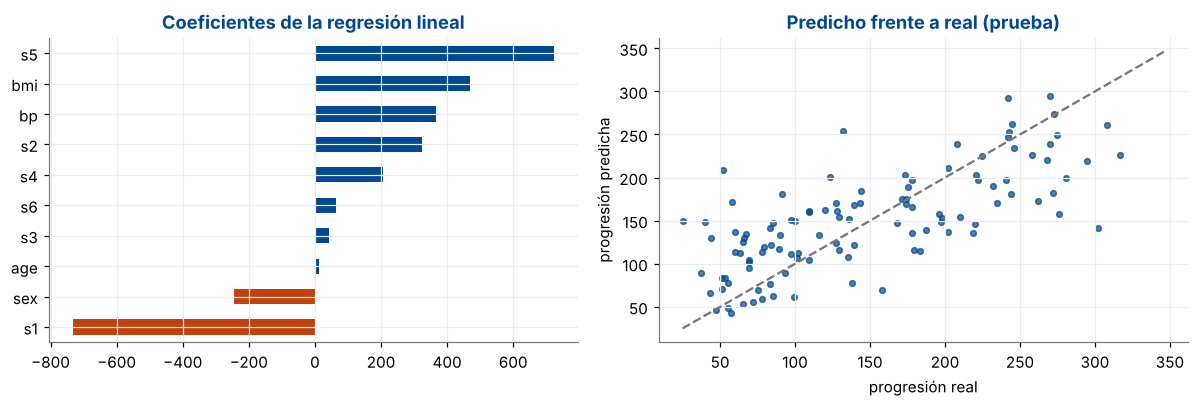

In [7]:
coef = pd.Series(lineal.coef_, index=X.columns).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
coef.plot.barh(ax=ax[0], color=[UNIBE["naranja"] if v < 0 else UNIBE["azul"] for v in coef])
ax[0].set_title("Coeficientes de la regresión lineal")
ax[1].scatter(y_te, lineal.predict(X_te), s=14, alpha=0.7)
ax[1].plot([25, 346], [25, 346], color=UNIBE["gris"], ls="--")
ax[1].set(xlabel="progresión real", ylabel="progresión predicha", title="Predicho frente a real (prueba)")
plt.tight_layout(); plt.show()

## Parte 2 · Regularización: cuando hay demasiadas variables

Agreguemos flexibilidad: todas las variables al cuadrado y todos los productos entre pares (`PolynomialFeatures(degree=2)`). Pasamos de 10 a 65 variables con solo 331 pacientes de entrenamiento: el modelo puede empezar a ajustar ruido. Ridge y Lasso castigan los coeficientes grandes; la fuerza `alpha` se elige por validación cruzada.

In [8]:
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

poli = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
ridge = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))).fit(X_tr, y_tr)

# TODO: arma el mismo pipeline con LassoCV(alphas=np.logspace(-0.5, 1.5, 30), cv=5, max_iter=50000, random_state=SEED) y entrénalo.
lasso = make_pipeline(PolynomialFeatures(degree=2, include_bias=False), StandardScaler(),
                      LassoCV(alphas=np.logspace(-0.5, 1.5, 30), cv=5, max_iter=50000, random_state=SEED)).fit(X_tr, y_tr)

for nombre, m in [("Lineal (10 variables)", lineal), ("Lineal (65 variables)", poli), ("Ridge (65 variables)", ridge), ("Lasso (65 variables)", lasso)]:
    informe(nombre, y_te, m.predict(X_te))
ceros = int(np.sum(lasso[-1].coef_ == 0))
print(f"\nLasso anuló {ceros} de 65 coeficientes · alpha elegido = {lasso[-1].alpha_:.3f}")

Lineal (10 variables)  MAE =   42.7 · RMSE =   54.1 · R² =  0.52
Lineal (65 variables)  MAE =   53.6 · RMSE =   68.9 · R² =  0.23
Ridge (65 variables)   MAE =   45.7 · RMSE =   56.6 · R² =  0.48
Lasso (65 variables)   MAE =   43.8 · RMSE =   53.7 · R² =  0.53

Lasso anuló 44 de 65 coeficientes · alpha elegido = 2.921


In [9]:
assert r2_score(y_te, poli.predict(X_te)) < r2_lin, "Con 65 variables sin regularizar, el modelo debería empeorar en la prueba."
assert ceros > 20, "Lasso debería anular buena parte de los coeficientes."
print("✓ Sin regularizar, más variables empeoran la prueba; Lasso selecciona variables.")

✓ Sin regularizar, más variables empeoran la prueba; Lasso selecciona variables.


## Parte 3 · Clasificación: de Iris a un diagnóstico real

Ahora la respuesta es una **categoría**: un problema de **clasificación**. Empezamos con el conjunto más famoso de la historia del ML: **Iris** (Fisher, 1936), 150 flores de tres especies con cuatro medidas de pétalos y sépalos.

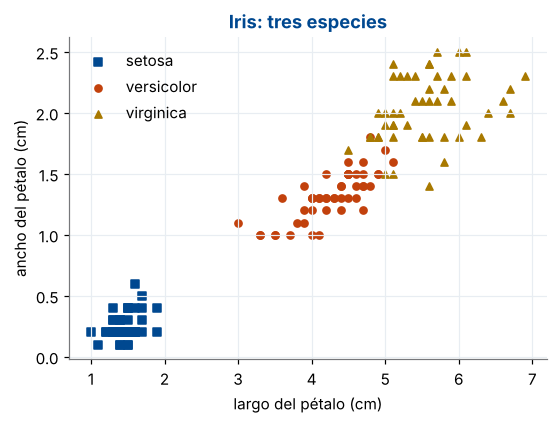

In [10]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
Xi, yi = iris.data, iris.target
nombres = iris.target_names
fig, ax = plt.subplots(figsize=(5.6, 3.8))
for k, (marca, color) in enumerate(zip("so^", [UNIBE["azul"], UNIBE["naranja"], UNIBE["dorado"]])):
    ax.scatter(Xi.loc[yi == k, "petal length (cm)"], Xi.loc[yi == k, "petal width (cm)"], marker=marca, color=color, label=nombres[k], s=22)
ax.set(xlabel="largo del pétalo (cm)", ylabel="ancho del pétalo (cm)", title="Iris: tres especies")
ax.legend(); plt.show()

**Logística binaria.** *Setosa* se separa sola; lo interesante es distinguir **versicolor** de **virginica**, que se solapan. Usamos las dos medidas del pétalo para poder dibujar la frontera $p = 0.5$.

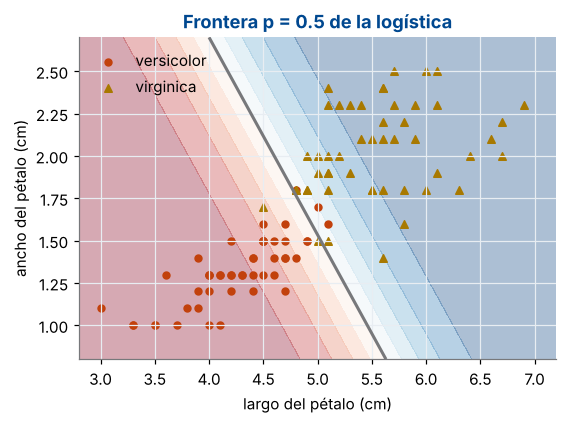

Exactitud de entrenamiento: 95% · coeficientes: [[2.78 2.39]]


In [11]:
from sklearn.linear_model import LogisticRegression

mask = yi > 0
Xb2, yb2 = Xi.loc[mask, ["petal length (cm)", "petal width (cm)"]].to_numpy(), (yi[mask] == 2).astype(int).to_numpy()
log2 = LogisticRegression().fit(Xb2, yb2)
xx, yy = np.meshgrid(np.linspace(2.8, 7.2, 200), np.linspace(0.8, 2.7, 200))
pp = log2.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.contourf(xx, yy, pp, levels=np.linspace(0, 1, 11), cmap="RdBu", alpha=0.35)
ax.contour(xx, yy, pp, levels=[0.5], colors=UNIBE["gris"], linewidths=2)
ax.scatter(*Xb2[yb2 == 0].T, marker="o", color=UNIBE["naranja"], s=20, label="versicolor")
ax.scatter(*Xb2[yb2 == 1].T, marker="^", color=UNIBE["dorado"], s=24, label="virginica")
ax.set(xlabel="largo del pétalo (cm)", ylabel="ancho del pétalo (cm)", title="Frontera p = 0.5 de la logística")
ax.legend(); plt.show()
print("Exactitud de entrenamiento:", f"{log2.score(Xb2, yb2):.0%}", "· coeficientes:", log2.coef_.round(2))

**Tu turno.** ¿Qué probabilidad de ser *virginica* le asigna el modelo a una flor con pétalo de 5.0 × 1.7 cm? ¿Y a una de 6.0 × 2.2 cm?

In [12]:
# TODO: usa log2.predict_proba con las dos flores y guarda las dos probabilidades de virginica en p_flores.
p_flores = log2.predict_proba(np.array([[5.0, 1.7], [6.0, 2.2]]))[:, 1]
print("p(virginica):", p_flores.round(2))
assert p_flores[1] > 0.9 > p_flores[0], "La flor grande debería ser virginica casi con certeza; la otra, dudosa."

p(virginica): [0.6  0.99]


**Con las tres especies.** La logística se extiende a $K$ clases con **softmax** (M1 §4): un puntaje por clase, convertidos en probabilidades que suman 1. Evaluamos con validación cruzada de 5 pliegues.

In [13]:
from sklearn.model_selection import cross_val_score

softmax = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
cv_iris = cross_val_score(softmax, Xi, yi, cv=5)
print(f"Iris, 3 clases: exactitud CV = {cv_iris.mean():.3f} ± {cv_iris.std():.3f}")
print("Probabilidades de la primera flor:", softmax.fit(Xi, yi).predict_proba(Xi.iloc[:1]).round(3), "→ suman", softmax.predict_proba(Xi.iloc[:1]).sum())

Iris, 3 clases: exactitud CV = 0.960 ± 0.039
Probabilidades de la primera flor: [[0.985 0.015 0.   ]] → suman 1.0


### Escala realista: Breast Cancer Wisconsin

569 tumores de mama. Para cada uno, 30 medidas calculadas a partir de una imagen digitalizada de una punción con aguja fina (radio, textura, concavidad… de los núcleos celulares). La respuesta: **maligno o benigno**. Atención: en scikit-learn la clase **0 es maligno** y la 1 benigno; aquí la invertimos para que «positivo» signifique maligno.

(569, 30) · malignos: 212 · benignos: 357
Exactitud = 0.965 · recall de malignos = 0.925


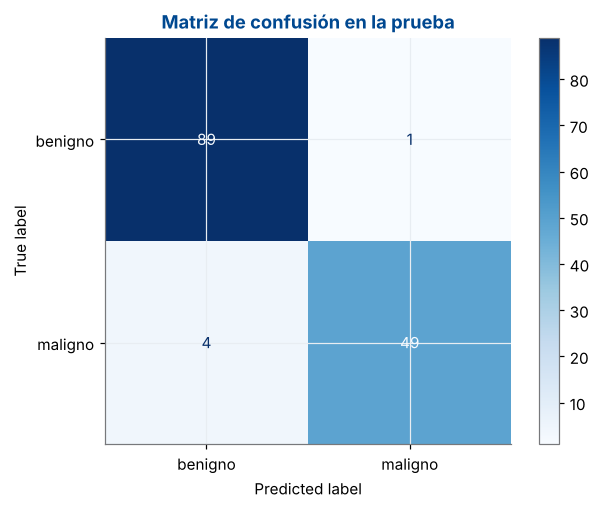

In [14]:
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import ConfusionMatrixDisplay, recall_score

bc = load_breast_cancer(as_frame=True)
Xc, yc = bc.data, 1 - bc.target          # 1 = maligno
print(Xc.shape, "· malignos:", int(yc.sum()), "· benignos:", int((1 - yc).sum()))
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=SEED)

# TODO: arma un pipeline StandardScaler + LogisticRegression(max_iter=1000), entrénalo y calcula el recall de malignos en la prueba.
diag = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xc_tr, yc_tr)
rec = recall_score(yc_te, diag.predict(Xc_te))
print(f"Exactitud = {diag.score(Xc_te, yc_te):.3f} · recall de malignos = {rec:.3f}")
ConfusionMatrixDisplay.from_estimator(diag, Xc_te, yc_te, display_labels=["benigno", "maligno"], cmap="Blues")
plt.title("Matriz de confusión en la prueba"); plt.show()
assert rec > 0.9

Cada falso negativo es un tumor maligno que el modelo llamó benigno. ¿Qué pasa con el recall si marcamos «maligno» desde una probabilidad de 0.2 en lugar de 0.5?

In [15]:
p_mal = diag.predict_proba(Xc_te)[:, 1]
for t in (0.5, 0.2):
    pred = (p_mal >= t).astype(int)
    fn, fp = int(((pred == 0) & (yc_te == 1)).sum()), int(((pred == 1) & (yc_te == 0)).sum())
    print(f"umbral {t}: recall = {recall_score(yc_te, pred):.3f} · falsos negativos = {fn} · falsos positivos = {fp}")

umbral 0.5: recall = 0.925 · falsos negativos = 4 · falsos positivos = 1
umbral 0.2: recall = 0.943 · falsos negativos = 3 · falsos positivos = 5


## Parte 4 · Reflexión

1. Escribe dos problemas de tu trabajo: uno de regresión y uno de clasificación. ¿Qué sería el baseline en cada uno?
2. En diabetes, ¿por qué el modelo con 65 variables empeoró en la prueba si en entrenamiento es mejor?
3. En el diagnóstico de cáncer, ¿qué umbral elegirías y por qué? ¿Quién debería decidirlo?

> **Respuesta de referencia**

1. Por ejemplo: el consumo eléctrico de mañana (regresión; baseline = el consumo de hoy o el promedio del mismo día de la semana) y si un cliente pagará a tiempo (clasificación; baseline = la clase más frecuente).
2. Con 65 variables y 331 pacientes, los mínimos cuadrados ajustan también el ruido de la muestra de entrenamiento (varianza alta): el error de entrenamiento baja, pero el de prueba sube. Ridge y Lasso controlan esa varianza.
3. Un umbral bajo (por ejemplo 0.2) reduce los falsos negativos a costa de más falsos positivos, que significan pruebas adicionales. La decisión es clínica: el costo de cada error lo define el equipo médico; el modelo solo entrega probabilidades.

## Desafío opcional con IA agéntica · Del icónico al realista, con un agente

**Objetivo.** Pedirle a un asistente de IA que lleve el flujo de diabetes a un problema de regresión más realista y revisar críticamente lo que hace.

**Prompt inicial.** Úsalo en la herramienta que prefieras (Claude Code, Codex, Gemini en Colab, ChatGPT…), con este notebook resuelto como contexto. Pide primero un plan y revisa cada paso antes de aprobarlo.

```text
Tengo el notebook resuelto L1.1 (regresión lineal, Ridge y Lasso con el conjunto diabetes de scikit-learn). Muéstrame primero un plan y espera mi aprobación. Luego agrega una sección que repita el análisis con California Housing (sklearn.datasets.fetch_california_housing): baseline con DummyRegressor, regresión lineal, Ridge y Lasso dentro de pipelines con StandardScaler, validación cruzada de 5 pliegues sin tocar la prueba, y una tabla de MAE, RMSE y R² en la prueba. Explica en dos frases si el problema del modelo lineal es de sesgo o de varianza.
```

**Cómo verificar el resultado**

- La prueba se separa antes de todo y se usa una sola vez.
- El escalado está dentro del pipeline, no aplicado a todo el conjunto.
- La conclusión sobre sesgo o varianza se apoya en las cifras de entrenamiento y validación, no en una intuición.

**Declara el uso de IA** (como pide el sílabo): herramienta, prompts relevantes, qué verificaste tú y qué corregiste. El desafío es opcional y no se califica; lo que cuenta es que puedas explicar cada decisión.